In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

from setup_dsp import *


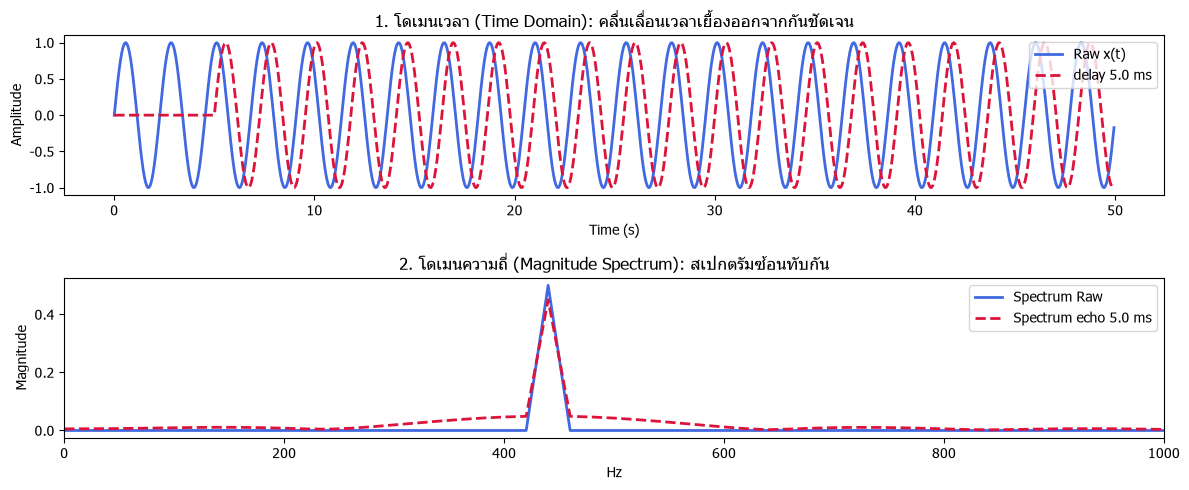

In [2]:
fs = 16000           
duration = 0.05
t = time_axis(fs, duration)
raw = generate_sine(440,t)
echo = generate_sine(440,t)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
echo = np.zeros_like(raw)
echo[delay_samples:] = raw[:-delay_samples]

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t * 1000,raw, label="Raw x(t)", color="royalblue", lw=2)
plt.plot(t * 1000, echo, label=f"delay {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()

plt.subplot(2,1,2)
plt.plot(freqs, mag_raw, label="Spectrum Raw", color="royalblue", lw=2)
plt.plot(freqs, mag_echo, label=f"Spectrum echo {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกัน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.legend(loc="upper right")
plt.xlim(0, 1000)
plt.tight_layout()


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 5.00 ms (80 samples)


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 12.00 ms (192 samples)


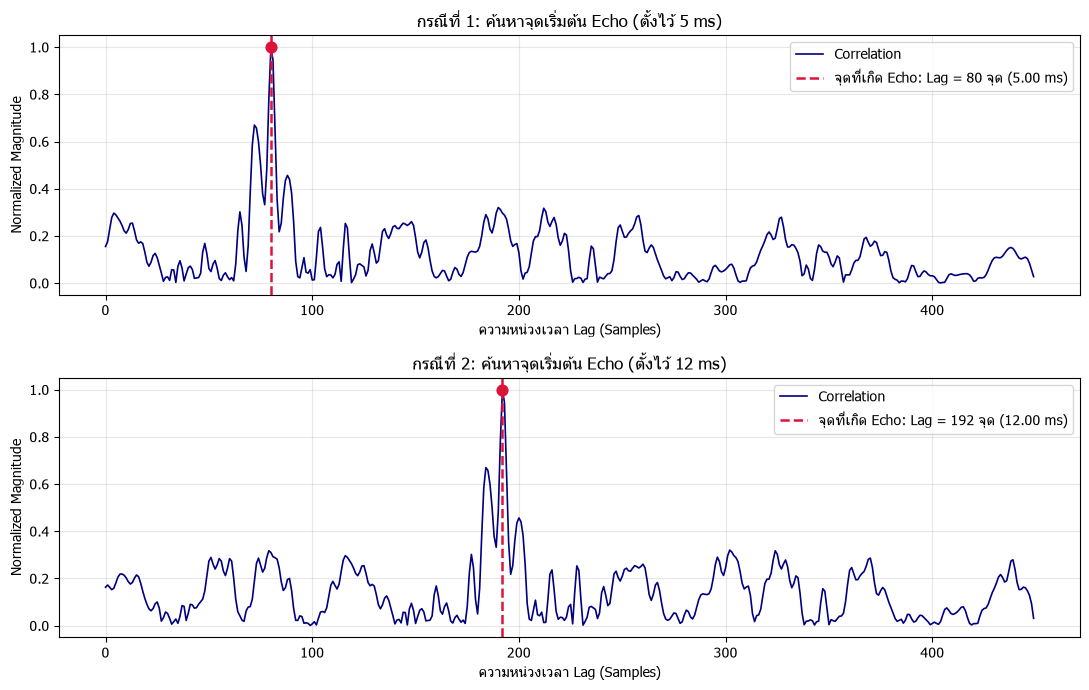

In [3]:
# ==========================================================
# 1. กรณีที่ 1: Echo Lag 5 ms (80 samples)
# ==========================================================
t, raw, echo1, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=5)

seg_len = fs * 1
corr1 = np.correlate(echo1[:seg_len], raw[:seg_len], mode="full")
lags = np.arange(-seg_len + 1, seg_len)

max_lag_show = 450
zero_idx = seg_len - 1

lags_view = lags[zero_idx : zero_idx + max_lag_show]
corr_view1 = np.abs(corr1[zero_idx : zero_idx + max_lag_show])
corr_view1 = corr_view1 / np.max(corr_view1)

lag1 = lags_view[np.argmax(corr_view1)]
ms1 = lag1 / fs * 1000

# ==========================================================
# 2. กรณีที่ 2: Echo Lag 12 ms (192 samples)
# ==========================================================
_, _, echo2, _ = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=12)

corr2 = np.correlate(echo2[:seg_len], raw[:seg_len], mode="full")
corr_view2 = np.abs(corr2[zero_idx : zero_idx + max_lag_show])
corr_view2 = corr_view2 / np.max(corr_view2)

lag2 = lags_view[np.argmax(corr_view2)]
ms2 = lag2 / fs * 1000

# ==========================================================
# 3. พล็อตกราฟเปรียบเทียบ 2 อัน
# ==========================================================
plt.figure(figsize=(11, 7))

# กราฟที่ 1 (5 ms)
plt.subplot(2, 1, 1)
plt.plot(lags_view, corr_view1, color="navy", linewidth=1.2, label="Correlation")
plt.axvline(lag1, color="crimson", linestyle="--", linewidth=1.8, label=f"จุดที่เกิด Echo: Lag = {lag1} จุด ({ms1:.2f} ms)")
plt.scatter([lag1], [1.0], color="crimson", s=60, zorder=5)
plt.title("กรณีที่ 1: ค้นหาจุดเริ่มต้น Echo (ตั้งไว้ 5 ms)")
plt.xlabel("ความหน่วงเวลา Lag (Samples)")
plt.ylabel("Normalized Magnitude")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

# กราฟที่ 2 (12 ms)
plt.subplot(2, 1, 2)
plt.plot(lags_view, corr_view2, color="navy", linewidth=1.2, label="Correlation")
plt.axvline(lag2, color="crimson", linestyle="--", linewidth=1.8, label=f"จุดที่เกิด Echo: Lag = {lag2} จุด ({ms2:.2f} ms)")
plt.scatter([lag2], [1.0], color="crimson", s=60, zorder=5)
plt.title("กรณีที่ 2: ค้นหาจุดเริ่มต้น Echo (ตั้งไว้ 12 ms)")
plt.xlabel("ความหน่วงเวลา Lag (Samples)")
plt.ylabel("Normalized Magnitude")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
